Imports das bibliotecas

In [1]:
import os
from pathlib import Path
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

Definir caminhos e classe de Dataset customizada

In [ ]:
# Versao fixa para manter os dados das experiencias reproduziveis.
DATASET_HANDLE = "mostafaabla/garbage-classification/versions/1"
path = Path(kagglehub.dataset_download(DATASET_HANDLE))
print("Path to dataset files:", path)
DATASET_PATH = path / "garbage_classification"
EXPECTED_CLASSES = {
    "battery", "biological", "brown-glass", "cardboard", "clothes", "green-glass",
    "metal", "paper", "plastic", "shoes", "trash", "white-glass",
}
if not DATASET_PATH.is_dir():
    raise FileNotFoundError(f"Diretorio das classes nao encontrado: {DATASET_PATH}")
if {p.name for p in DATASET_PATH.iterdir() if p.is_dir()} != EXPECTED_CLASSES:
    raise ValueError(f"Classes inesperadas em {DATASET_PATH}")

def fix_path(image_path):
    # Reutilizar features com caminhos de outra maquina, sempre na versao fixa.
    parts = str(image_path).replace("\\", "/").split("/")
    resolved_path = DATASET_PATH.joinpath(*parts[-2:])
    if not resolved_path.is_file():
        raise FileNotFoundError(f"Imagem nao encontrada: {resolved_path}")
    return str(resolved_path)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Definir device (GPU se disponível, senão CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"A usar o dispositivo: {device}")

# Dataset customizado em PyTorch para percorrer a estrutura de pastas
class GarbageDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []
        
        # Guardar os nomes das pastas como classes
        self.class_names = sorted([d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))])
        self.class_to_idx = {class_name: i for i, class_name in enumerate(self.class_names)}
        
        for class_name in self.class_names:
            class_dir = os.path.join(root_dir, class_name)
            for img_name in os.listdir(class_dir):
                if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp')):
                    self.image_paths.append(os.path.join(class_dir, img_name))
                    self.labels.append(self.class_to_idx[class_name])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
            
        return image, label, img_path

Transforms e Carregamento do Modelo Extractor (MobileNetV2)

In [3]:
# Transformações padrão do PyTorch / ImageNet
transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

# Instanciar o Dataset e DataLoader
dataset = GarbageDataset(root_dir=DATASET_PATH, transform=transform)
dataloader = DataLoader(
    dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    num_workers=0,     # Mudar de 2 para 0 (evita congelar no Windows)
    pin_memory=True    # Acelera a passagem para a GPU
)
class_names = dataset.class_names
print("Classes encontradas:", class_names)

# Carregar MobileNetV2 pré-treinada do torchvision
weights = models.MobileNet_V2_Weights.DEFAULT
base_model = models.mobilenet_v2(weights=weights)

# Remover a camada de classificação final (classifier) para ter apenas o extractor de features
base_model.classifier = nn.Identity()
base_model = base_model.to(device)
base_model.eval()  # Modo de avaliação

print("Extractor de features PyTorch MobileNetV2 pronto!")

Classes encontradas: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Extractor de features PyTorch MobileNetV2 pronto!


 Extrair e Guardar as Features ($X$ e $y$)

In [4]:
X_features = []
y_labels = []
filenames = []

print(f"A extrair features na GPU ({device})...")

with torch.no_grad():
    # tqdm adiciona a barra de progresso em tempo real
    for images, labels, paths in tqdm(dataloader, desc="A processar batches"):
        images = images.to(device, non_blocking=True)
        features = base_model(images)  # Gera o vetor de 1280 features
        
        X_features.append(features.cpu().numpy())
        y_labels.extend(labels.numpy())
        filenames.extend(paths)

X_features = np.vstack(X_features)
y_labels = np.array(y_labels)

print(f"\nFormato da matriz de features (X): {X_features.shape}")
print(f"Formato do vetor de rótulos (y): {y_labels.shape}")

# Guardar em ficheiro .npz comprimido para usar mais tarde
np.savez_compressed(
    'garbage_features.npz',
    X=X_features,
    y=y_labels,
    class_names=class_names,
    filenames=filenames
)

print("Features e labels guardados em 'garbage_features.npz'!")

A extrair features na GPU (cuda)...


A processar batches: 100%|██████████| 485/485 [00:52<00:00,  9.20it/s]



Formato da matriz de features (X): (15515, 1280)
Formato do vetor de rótulos (y): (15515,)
Features e labels guardados em 'garbage_features.npz'!


Treino do Classificador Baseline

In [5]:
# Split Train / Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_features, 
    y_labels, 
    test_size=0.20, 
    random_state=42, 
    stratify=y_labels
)

# Treino de um modelo leve (Logistic Regression ou RandomForest)
classifier = LogisticRegression(max_iter=1000, random_state=42)
classifier.fit(X_train, y_train)

# Previsão e avaliação
y_pred = classifier.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Acurácia da Classificação Base (PyTorch + Logistic Regression): {acc * 100:.2f}%")

Acurácia da Classificação Base (PyTorch + Logistic Regression): 95.58%


Matriz de Confusão e Relatório de Classificação


--- Classification Report ---
              precision    recall  f1-score   support

     battery       0.94      0.96      0.95       189
  biological       0.98      0.99      0.98       197
 brown-glass       0.95      0.96      0.96       122
   cardboard       0.96      0.95      0.95       178
     clothes       0.99      0.98      0.99      1065
 green-glass       0.96      0.90      0.93       126
       metal       0.91      0.88      0.89       154
       paper       0.93      0.94      0.93       210
     plastic       0.86      0.90      0.88       173
       shoes       0.96      0.98      0.97       395
       trash       0.98      0.96      0.97       139
 white-glass       0.88      0.86      0.87       155

    accuracy                           0.96      3103
   macro avg       0.94      0.94      0.94      3103
weighted avg       0.96      0.96      0.96      3103



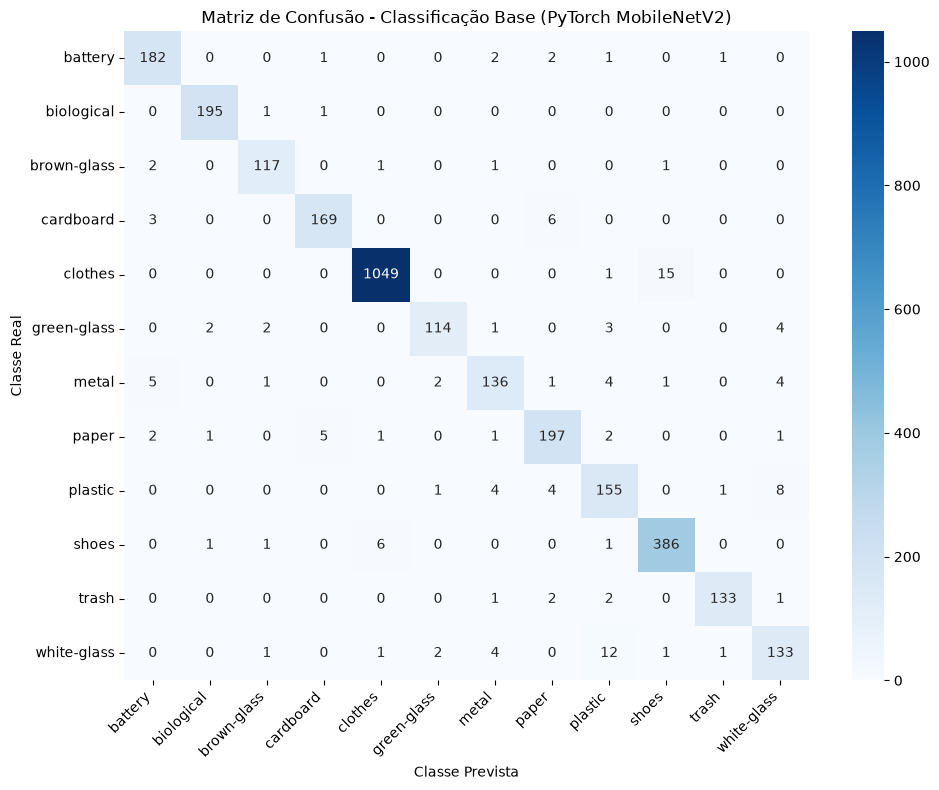

In [6]:
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusão - Classificação Base (PyTorch MobileNetV2)')
plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Active Learning + Human-in-the-Loop (HITL)

Carregar as Features salvas e preparar os Pools

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# 1. Carregar as features pré-calculadas
data = np.load('garbage_features.npz')
X = data['X']
y = data['y']
class_names = list(data['class_names'])
filenames = [fix_path(f) for f in data['filenames']]

print(f"Total de amostras carregadas: {X.shape[0]}")

# 2. Criar um split inicial: Labeled Pool (ex: 2% dos dados) e Unlabeled Pool (98%)
np.random.seed(42)
n_initial = int(0.02 * len(X))  # ~310 amostras rotuladas inicialmente

indices = np.arange(len(X))
np.random.shuffle(indices)

labeled_idx = list(indices[:n_initial])
unlabeled_idx = list(indices[n_initial:])

print(f"Amostras iniciais rotuladas (Labeled Pool): {len(labeled_idx)}")
print(f"Amostras no reservatório não rotulado (Unlabeled Pool): {len(unlabeled_idx)}")

Total de amostras carregadas: 15515
Amostras iniciais rotuladas (Labeled Pool): 310
Amostras no reservatório não rotulado (Unlabeled Pool): 15205


Definir as Estratégias de Seleção (Query Strategies)

In [8]:
def least_confidence_query(probs, n_samples=1):
    """Escolhe as instâncias onde a probabilidade da classe mais provável é menor."""
    uncertainties = 1 - np.max(probs, axis=1)
    return np.argsort(uncertainties)[-n_samples:]

def margin_query(probs, n_samples=1):
    """Escolhe as instâncias com menor diferença entre a 1ª e a 2ª classe mais provável."""
    sorted_probs = np.sort(probs, axis=1)
    margins = sorted_probs[:, -1] - sorted_probs[:, -2]
    return np.argsort(margins)[:n_samples]

def entropy_query(probs, n_samples=1):
    """Escolhe as instâncias com maior entropia (maior desordem nas probabilidades)."""
    # Adiciona ePS para evitar log(0)
    entropies = -np.sum(probs * np.log(probs + 1e-10), axis=1)
    return np.argsort(entropies)[-n_samples:]

def random_query(probs, n_samples=1):
    """Baseline: Escolha aleatória de instâncias."""
    return np.random.choice(len(probs), size=n_samples, replace=False)

Interface Interativa HITL no Jupyter (Jupyter Widgets)

In [9]:
import ipywidgets as widgets
from IPython.display import display, clear_output

class HITLLabeler:
    def __init__(self, X, y, filenames, class_names, labeled_idx, unlabeled_idx):
        self.X = X
        self.y = y
        self.filenames = filenames
        self.class_names = class_names
        self.labeled_idx = list(labeled_idx)
        self.unlabeled_idx = list(unlabeled_idx)
        
        self.model = LogisticRegression(max_iter=1000, random_state=42)
        self.model.fit(self.X[self.labeled_idx], self.y[self.labeled_idx])
        
        self.current_query_idx = None
        self.setup_ui()

    def setup_ui(self):
        self.out = widgets.Output()
        self.buttons = []
        
        # Botões para cada uma das 12 classes
        for i, name in enumerate(self.class_names):
            btn = widgets.Button(description=name, button_style='primary' if i % 2 == 0 else 'info')
            btn.on_click(self.make_label_callback(i))
            self.buttons.append(btn)
        
        self.grid = widgets.GridBox(self.buttons, layout=widgets.Layout(grid_template_columns="repeat(4, 200px)"))

    def make_label_callback(self, label_id):
        def callback(b):
            # Adicionar a amostra selecionada ao Labeled Pool com o rótulo do humano
            self.labeled_idx.append(self.current_query_idx)
            self.unlabeled_idx.remove(self.current_query_idx)
            
            # Re-treinar o modelo
            self.model.fit(self.X[self.labeled_idx], self.y[self.labeled_idx])
            
            # Próxima iteração
            self.next_iteration()
        return callback

    def next_iteration(self):
        with self.out:
            clear_output(wait=True)
            if len(self.unlabeled_idx) == 0:
                print("Todas as imagens foram rotuladas!")
                return
            
            # Calcular probabilidades para o Unlabeled Pool
            probs = self.model.predict_proba(self.X[self.unlabeled_idx])
            
            # Usar Least Confidence para encontrar a imagem com maior incerteza
            relative_query_pos = least_confidence_query(probs, n_samples=1)[0]
            self.current_query_idx = self.unlabeled_idx[relative_query_pos]
            
            # Mostrar imagem e incerteza
            img_path = self.filenames[self.current_query_idx]
            top_prob = np.max(probs[relative_query_pos])
            print(f"--- Human-in-the-Loop Active Learning ---")
            print(f"Imagens Rotuladas: {len(self.labeled_idx)} | Restantes: {len(self.unlabeled_idx)}")
            print(f"Confiança Atual do Modelo nesta imagem: {top_prob*100:.1f}%\n")
            
            display(Image.open(img_path).resize((250, 250)))

    def start(self):
        display(self.out)
        display(self.grid)
        self.next_iteration()

# Para Iniciar a Interface:
# labeler = HITLLabeler(X, y, filenames, class_names, labeled_idx, unlabeled_idx)
# labeler.start()

Código para a Simulação Automática

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from tqdm import tqdm

# 1. Carregar as features do ficheiro .npz
data = np.load('garbage_features.npz')
X = data['X']
y = data['y']
class_names = list(data['class_names'])

# 2. Definir as Query Strategies
def least_confidence_query(probs, n_samples=10):
    uncertainties = 1 - np.max(probs, axis=1)
    return np.argsort(uncertainties)[-n_samples:]

def margin_query(probs, n_samples=10):
    sorted_probs = np.sort(probs, axis=1)
    margins = sorted_probs[:, -1] - sorted_probs[:, -2]
    return np.argsort(margins)[:n_samples]

def entropy_query(probs, n_samples=10):
    entropies = -np.sum(probs * np.log(probs + 1e-10), axis=1)
    return np.argsort(entropies)[-n_samples:]

def random_query(probs, n_samples=10):
    return np.random.choice(len(probs), size=n_samples, replace=False)

# 3. Parâmetros do Experimento
N_INITIAL = 200      # Labeled pool inicial (~1.3% do dataset)
N_ITERATIONS = 40    # Número de iterações de rotulagem
BATCH_SIZE = 20      # Imagens rotuladas por iteração (Total final = 200 + 40*20 = 1000 amostras)

strategies = {
    'Random (Baseline)': random_query,
    'Least Confidence': least_confidence_query,
    'Margin Sampling': margin_query,
    'Entropy Sampling': entropy_query
}

# Fixar conjunto de Teste independente para avaliação (20% dos dados)
np.random.seed(42)
test_idx = np.random.choice(len(X), size=int(0.2 * len(X)), replace=False)
train_pool_idx = np.setdiff1d(np.arange(len(X)), test_idx)

X_test, y_test = X[test_idx], y[test_idx]

# Guardar histórico de acurácia por estratégia
results = {strat: [] for strat in strategies}
sample_counts = [N_INITIAL + i * BATCH_SIZE for i in range(N_ITERATIONS + 1)]

# 4. Executar a Simulação Comparativa
for name, query_fn in strategies.items():
    print(f"\nA simular Active Learning com estratégia: {name}...")
    
    # Criar split inicial idêntico para todas as estratégias
    np.random.seed(42)
    initial_labeled = np.random.choice(train_pool_idx, size=N_INITIAL, replace=False)
    
    labeled_idx = list(initial_labeled)
    unlabeled_idx = list(np.setdiff1d(train_pool_idx, initial_labeled))
    
    # Modelo
    clf = LogisticRegression(max_iter=1000, random_state=42)
    
    for iteration in tqdm(range(N_ITERATIONS + 1), desc=f"{name}"):
        # Treinar com o Labeled Pool atual
        clf.fit(X[labeled_idx], y[labeled_idx])
        
        # Avaliar no Test Set fixo
        y_pred = clf.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        results[name].append(acc)
        
        if iteration < N_ITERATIONS:
            # Prever probabilidades do Unlabeled Pool
            probs = clf.predict_proba(X[unlabeled_idx])
            
            # Escolher as PEORES/MAIS INCERTAS instâncias segundo a estratégia
            query_pos = query_fn(probs, n_samples=BATCH_SIZE)
            
            # Mover das unlabeled para as labeled
            selected_indices = [unlabeled_idx[p] for p in query_pos]
            labeled_idx.extend(selected_indices)
            
            # Remover selecionadas do unlabeled_idx
            unlabeled_idx = list(np.setdiff1d(unlabeled_idx, selected_indices))

print("\nSimulação concluída com sucesso!")



A simular Active Learning com estratégia: Random (Baseline)...


Random (Baseline): 100%|██████████| 41/41 [00:09<00:00,  4.40it/s]



A simular Active Learning com estratégia: Least Confidence...


Least Confidence: 100%|██████████| 41/41 [00:11<00:00,  3.55it/s]



A simular Active Learning com estratégia: Margin Sampling...


Margin Sampling: 100%|██████████| 41/41 [00:12<00:00,  3.18it/s]



A simular Active Learning com estratégia: Entropy Sampling...


Entropy Sampling: 100%|██████████| 41/41 [00:11<00:00,  3.71it/s]


Simulação concluída com sucesso!


Gerar o Gráfico de Comparação (Curvas de Aprendizagem)

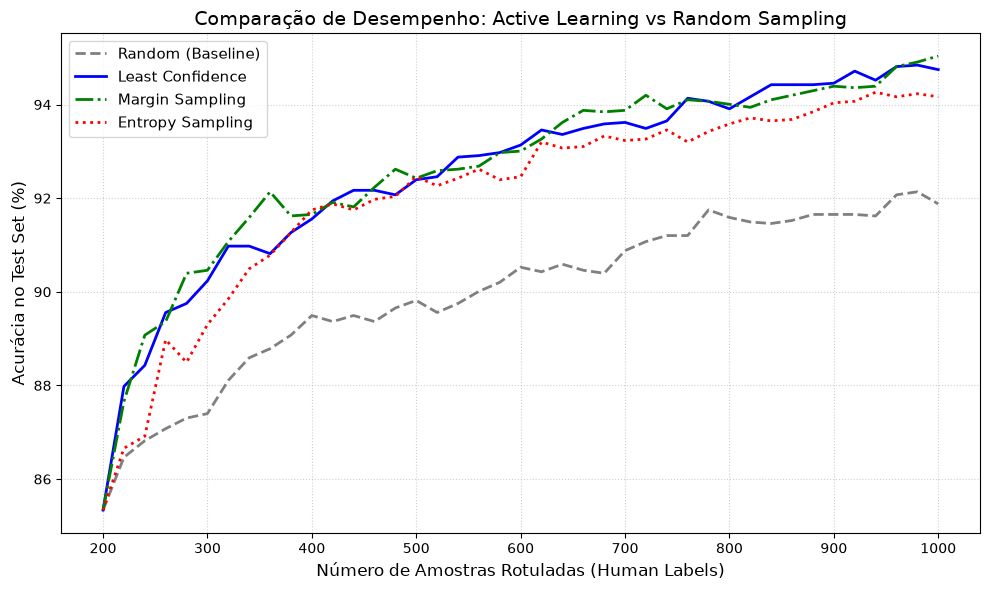

In [11]:
plt.figure(figsize=(10, 6))

styles = {
    'Random (Baseline)': ('--', 'gray'),
    'Least Confidence': ('-', 'blue'),
    'Margin Sampling': ('-.', 'green'),
    'Entropy Sampling': (':', 'red')
}

for name, acc_list in results.items():
    linestyle, color = styles[name]
    plt.plot(sample_counts, np.array(acc_list) * 100, label=name, linestyle=linestyle, color=color, linewidth=2)

plt.title('Comparação de Desempenho: Active Learning vs Random Sampling', fontsize=14)
plt.xlabel('Número de Amostras Rotuladas (Human Labels)', fontsize=12)
plt.ylabel('Acurácia no Test Set (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Fase 3: Preparar a Interface Interativa Human-in-the-Loop (HITL)

In [14]:
import os
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output
from sklearn.linear_model import LogisticRegression

# 1. Carregar as features e caminhos dos ficheiros
data = np.load('garbage_features.npz')
X = data['X']
y_true = data['y']
class_names = list(data['class_names'])
filenames = [fix_path(f) for f in data['filenames']]

# 3. Criar os Pools Iniciais
np.random.seed(42)
N_START = 150

all_idx = np.arange(len(X))
np.random.shuffle(all_idx)

user_labeled_idx = list(all_idx[:N_START])
user_unlabeled_idx = list(all_idx[N_START:])
user_labels = {idx: y_true[idx] for idx in user_labeled_idx}

# Treinar modelo inicial
hitl_model = LogisticRegression(max_iter=1000, random_state=42)
hitl_model.fit(X[user_labeled_idx], [user_labels[i] for i in user_labeled_idx])

# 4. Criar os Elementos da Interface
img_widget = widgets.Image(format='jpeg', width=300, height=300)
info_label = widgets.HTML()
out = widgets.Output()

def get_next_uncertain_sample():
    probs = hitl_model.predict_proba(X[user_unlabeled_idx])
    uncertainties = 1 - np.max(probs, axis=1)
    most_uncertain_pos = np.argmax(uncertainties)
    return user_unlabeled_idx[most_uncertain_pos], probs[most_uncertain_pos]

current_sample_idx, current_probs = get_next_uncertain_sample()

def update_display():
    global current_sample_idx, current_probs
    
    # Atualizar imagem
    img_path = filenames[current_sample_idx]
    if os.path.exists(img_path):
        with open(img_path, "rb") as f:
            img_widget.value = f.read()
    else:
        info_label.value = f"<b style='color:red;'>Erro: Ficheiro não encontrado no caminho: {img_path}</b>"
        return

    # Atualizar texto explicativo
    top_pred_class = class_names[np.argmax(current_probs)]
    confidence = np.max(current_probs) * 100
    
    info_label.value = f"""
    <h3>=== SESSÃO INTERATIVA HUMAN-IN-THE-LOOP ===</h3>
    <p><b>Amostras Rotuladas:</b> {len(user_labeled_idx)} | <b>Restantes:</b> {len(user_unlabeled_idx)}</p>
    <p><b>Previsão do Modelo:</b> <span style='color:blue;'>{top_pred_class}</span> (Confiança: <b>{confidence:.1f}%</b>)</p>
    <p><i>Qual é a classe correta deste resíduo? Clica no botão correspondente abaixo:</i></p>
    """

def on_button_click(class_id):
    global current_sample_idx, current_probs
    
    # Guardar label e re-treinar
    user_labels[current_sample_idx] = class_id
    user_labeled_idx.append(current_sample_idx)
    user_unlabeled_idx.remove(current_sample_idx)
    
    hitl_model.fit(X[user_labeled_idx], [user_labels[i] for i in user_labeled_idx])
    
    # Próxima imagem
    current_sample_idx, current_probs = get_next_uncertain_sample()
    update_display()

# Criar os botões das 12 classes
buttons = []
for i, name in enumerate(class_names):
    btn = widgets.Button(
        description=name,
        button_style='primary' if i % 2 == 0 else 'info',
        layout=widgets.Layout(width='160px', height='38px', margin='3px')
    )
    btn.on_click(lambda b, cid=i: on_button_click(cid))
    buttons.append(btn)

grid = widgets.GridBox(buttons, layout=widgets.Layout(grid_template_columns="repeat(4, 170px)"))

# Apresentar a interface
display(info_label)
display(img_widget)
display(grid)

# Carregar a primeira imagem
update_display()

HTML(value='')

Image(value=b'', format='jpeg', height='300', width='300')

GridBox(children=(Button(button_style='primary', description=np.str_('battery'), layout=Layout(height='38px', …